## EN3160 Assignment 2 on Fitting and Alignment

##### Name : Rasanjana W.P.G.R.A.
##### Index Number : 230536E
Github Link : [https://github.com/rus1ru/EN3160_Assignment_1](https://github.com/rus1ru/EN3160_Assignment_1)

### Q1 : Blob Detection in a Sunflower Field

**Idea.** A sunflower head looks like a roughly round spot. We look for spots that stand out at several sizes, then draw a circle around each one. The lower-half boundary keeps the search on the field rather than the sky. A circle is only an estimate of a flower head, not a perfect outline.


In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

im = cv.imread("./images_02/the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(float)
sigmas = np.geomspace(1.5, 12, 40) #linspace but non-linear

roi_y = int(0.50 * gray.shape[0])  # A virtual boundry to only limit to sunflowers


In [15]:
# Scale-normalized LoG at each sigma.
scale_space = np.stack([
    s*s*gaussian_laplace(gray, s) for s in sigmas
], axis=-1)

peaks = (scale_space == maximum_filter(scale_space, size=3)) & (scale_space > 65)
peaks[:, :, [0, -1]] = False
ys, xs, ks = np.where(peaks)
radii = np.sqrt(2) * sigmas[ks]

# Discard circles extending beyond the image boundary.
valid = (xs-radii >= 0) & (ys-radii >= roi_y) & (xs+radii < gray.shape[1]) & (ys+radii < gray.shape[0])
xs, ys, ks, radii = xs[valid], ys[valid], ks[valid], radii[valid]


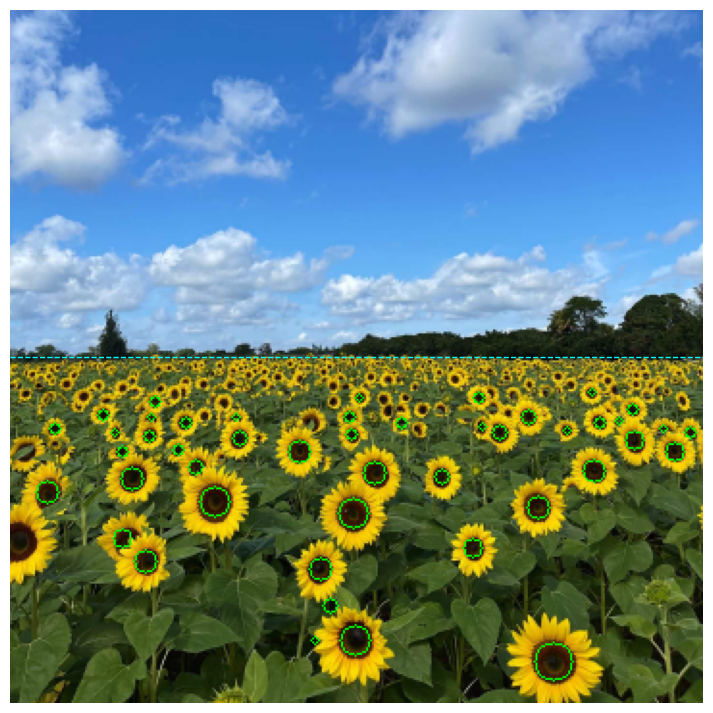

In [16]:
result = im.copy()
for x, y, r in zip(xs, ys, radii):
    cv.circle(result, (int(x), int(y)), round(r), (0, 255, 0), 1)

plt.figure(figsize=(9, 9))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axhline(roi_y, color="cyan", linestyle="--", linewidth=1)
plt.axis("off")
plt.show()



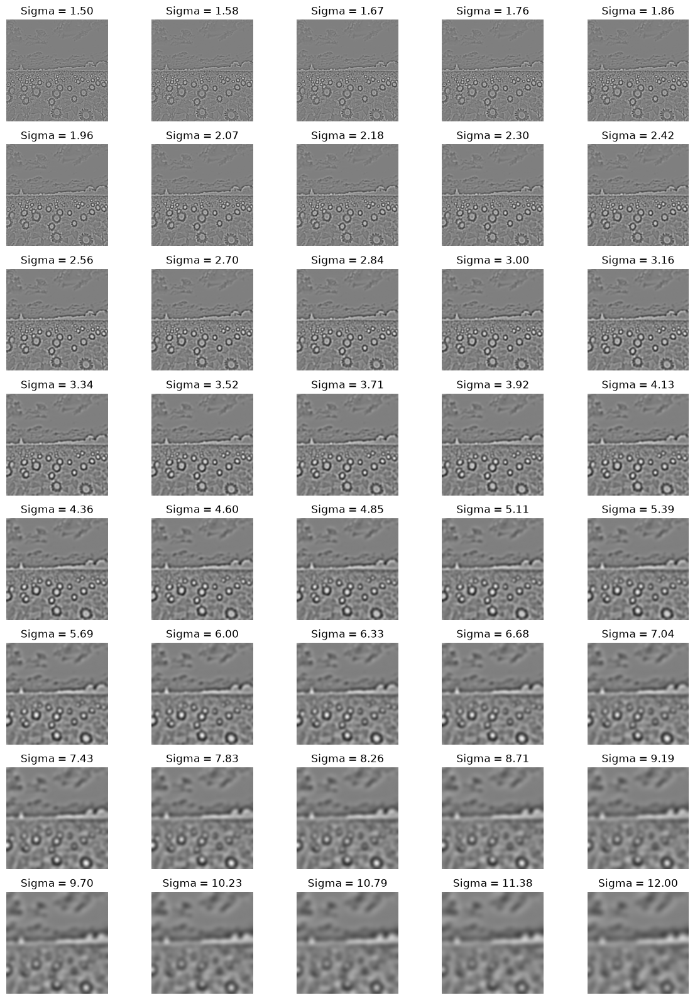

In [17]:
# Show the signed, scale-normalized LoG response at every sigma.
fig, axes = plt.subplots(8, 5, figsize=(12, 16))
limit = np.abs(scale_space).max()
for i, ax in enumerate(axes.flat):
    ax.imshow(scale_space[:, :, i], cmap="gray", vmin=-limit, vmax=limit)
    ax.set_title(f"Sigma = {sigmas[i]:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


**What to notice.** The circles change size because nearby and distant flower heads appear different in the photo. Some heads may be missed or grouped together; contrast and overlapping flowers make it hard to find every one. The chosen size range and cutoff affect how many circles appear.


### Q2 : Using RANSAC for paramterize a circle and a line

##### Generation of a Noisy Point Set Conforming to a Line and a Circle

**Idea.** Imagine the points as two overlapping sketches: one straight path and one ring. We first look for a line supported by many nearby points, set those points aside, then look for a circle among what remains. Trying many small random samples helps us avoid trusting one noisy pair or trio.


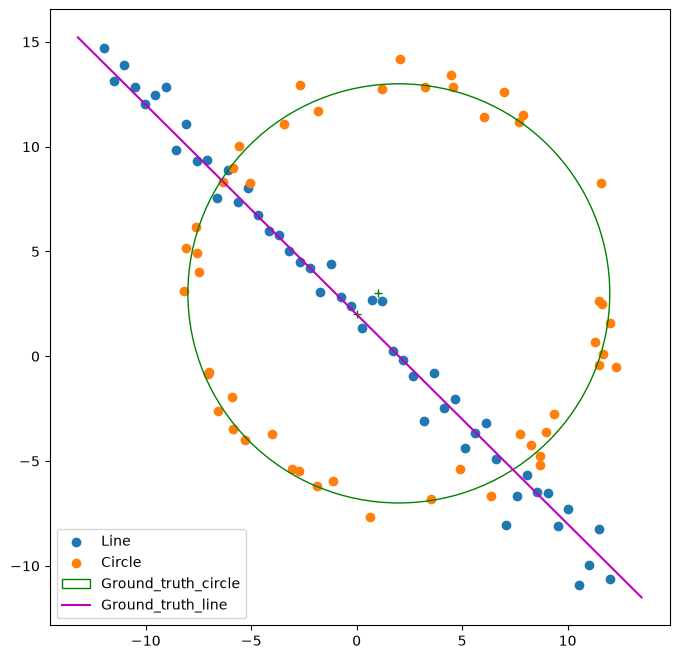

In [18]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3 # Center
s = r/16.
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line)) # All points

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground_truth_circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt, y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground_truth_line')
plt.legend()

In [19]:
import numpy as np

def line_from_two_points(points):
    p, q = points
    direction = q - p

    normal = np.array([-direction[1], direction[0]], dtype=float)
    length = np.linalg.norm(normal)

    if length < 1e-10:
        return None  # Coincident points cannot define a line

    normal /= length
    d = normal @ p

    if d < 0:
        normal, d = -normal, -d

    return normal, d

In [20]:
rng = np.random.default_rng(42)

threshold_line = 1.5
min_consensus = 35
best_inliers = np.zeros(len(X), dtype=bool)
best_error = np.inf

for _ in range(1000):
    sample = X[rng.choice(len(X), 2, replace=False)]
    model = line_from_two_points(sample)

    if model is None:
        continue

    normal, d = model
    errors = np.abs(X @ normal - d)
    inliers = errors < threshold_line
    count = inliers.sum()

    if count < min_consensus:
        continue

    mean_error = errors[inliers].mean()

    if (count > best_inliers.sum() or
        (count == best_inliers.sum() and mean_error < best_error)):
        best_normal = normal.copy()
        best_d = d
        best_inliers = inliers.copy()
        best_sample = sample.copy()
        best_error = mean_error

if not best_inliers.any():
    raise RuntimeError("No line reached the minimum consensus.")

print("Sample line normal:", best_normal)
print("Sample line d:", best_d)
print("Normal length:", np.linalg.norm(best_normal))
print("Consensus size:", best_inliers.sum())

Sample line normal: [0.72887972 0.68464177]
Sample line d: 1.3256145962816959
Normal length: 1.0
Consensus size: 56


In [21]:
remaining = X[~best_inliers]
print("Points remaining:", len(remaining))  # 46

Points remaining: 44


In [22]:
def circle_from_three_points(points):
    p, q, t = points

    A = 2 * np.array([q - p, t - p])
    B = np.array([q @ q - p @ p, t @ t - p @ p])

    if np.linalg.cond(A) > 1e8:
        return None  # Collinear or nearly collinear

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p - center)

    return center, radius

In [23]:
threshold_circle = 1.5
min_circle_consensus = 25

circle_inliers = np.zeros(len(remaining), dtype=bool)
best_circle_error = np.inf

for _ in range(1000):
    sample = remaining[rng.choice(len(remaining), 3, replace=False)]
    model = circle_from_three_points(sample)

    if model is None:
        continue

    center, radius = model

    errors = np.abs(np.linalg.norm(remaining - center, axis=1) - radius)
    inliers = errors < threshold_circle
    count = inliers.sum()

    if count < min_circle_consensus:
        continue

    mean_error = errors[inliers].mean()

    if (count > circle_inliers.sum() or
        (count == circle_inliers.sum() and mean_error < best_circle_error)):
        best_center = center.copy()
        best_radius = radius
        circle_inliers = inliers.copy()
        best_circle_sample = sample.copy()
        best_circle_error = mean_error

if not circle_inliers.any():
    raise RuntimeError("No circle reached the minimum consensus.")

print("Sample circle center:", best_center)
print("Sample circle radius:", best_radius)
print("Circle consensus:", circle_inliers.sum())

Sample circle center: [2.15553407 3.07487652]
Sample circle radius: 9.962975523184312
Circle consensus: 43


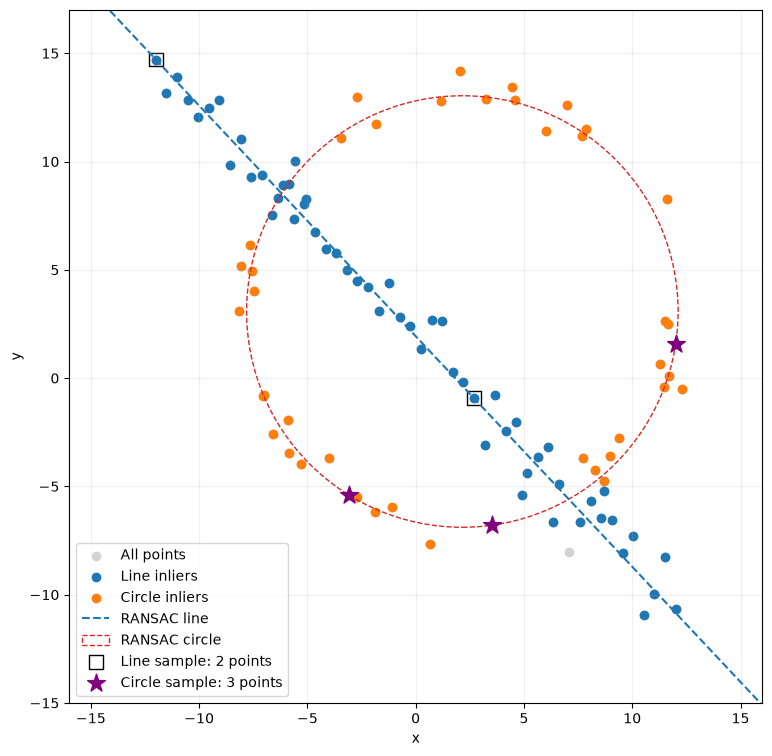

In [24]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(X[:, 0], X[:, 1], color="lightgray", label="All points")
ax.scatter(*X[best_inliers].T, color="tab:blue", label="Line inliers")
ax.scatter(*remaining[circle_inliers].T, color="tab:orange", label="Circle inliers")

# Draw ax + by = d without dividing by b.
u = np.linspace(-25, 25, 200)
direction = np.array([-best_normal[1], best_normal[0]])
line_points = best_d * best_normal + u[:, None] * direction
ax.plot(*line_points.T, "--", color="tab:blue", label="RANSAC line")
ax.add_patch(plt.Circle(best_center, best_radius, fill=False, linestyle="--",
                        color="tab:red", label="RANSAC circle"))

ax.scatter(*best_sample.T, marker="s", s=100,
           facecolors="none", edgecolors="black", label="Line sample: 2 points")
ax.scatter(*best_circle_sample.T, marker="*", s=180,
           color="purple", label="Circle sample: 3 points")

ax.set(xlim=(-16, 16), ylim=(-15, 17), xlabel="x", ylabel="y")
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**What to notice.** The blue and orange groups show which points each shape explains. The dashed shapes come from the selected samples, so noise can shift them slightly. Removing the line points first makes the circle easier to see; a circle fitted to all the points could also absorb some points from the line.


### Q3 : Homography

**Idea.** Imagine wrapping each JJK cover around one flat side of the monument. We tilt and stretch the covers, trim them at the edges of the stone, and let a little stone show through. The pointed roof is left alone.


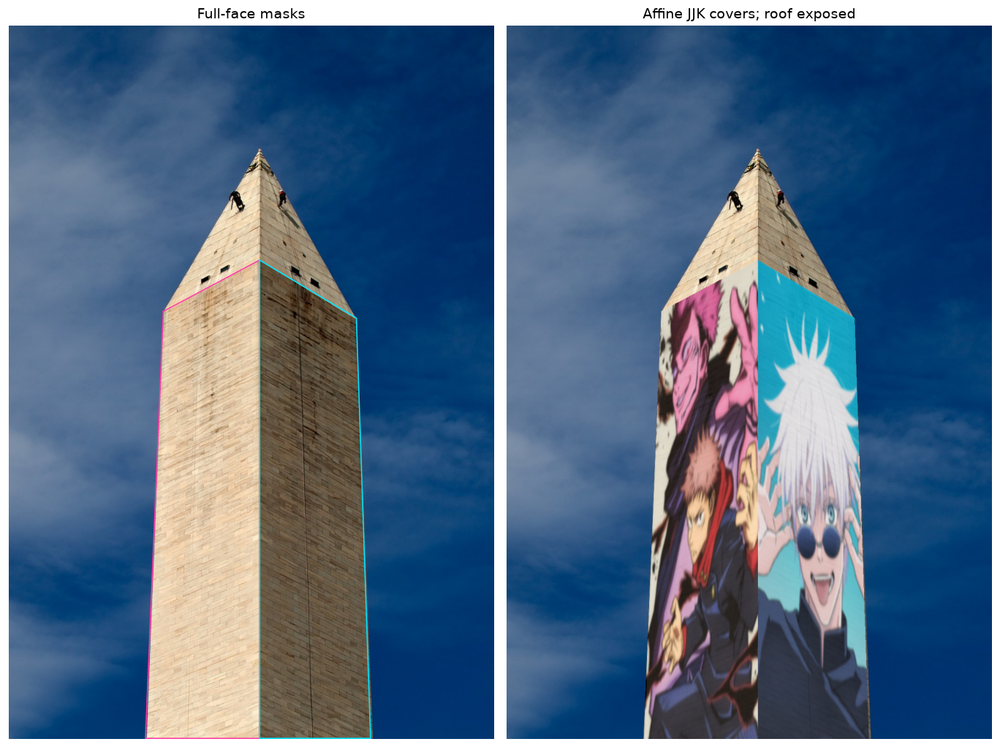

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

images = Path("images_02")
output = Path("results")
output.mkdir(exist_ok=True)
opacity = 0.85

scene = cv.imread(str(images / "monument.png"))
covers = [cv.imread(str(images / name)) for name in
          ("jjk_anime_s1_vol1.jpg", "jjk_anime_s2_vol1.png")]
if scene is None or any(cover is None for cover in covers):
    raise FileNotFoundError("Monument or JJK cover image not found in images_02")
h, w = scene.shape[:2]
if (w, h) != (1089, 1600):
    raise ValueError("Use the original uncropped 1089 x 1600 monument image")

# Four points define each visible face *mask*, not the affine transform.
faces = [np.float32([[347, 641], [563, 526], [563, 1599], [307, 1599]]),
         np.float32([[563, 526], [780, 656], [812, 1599], [563, 1599]])]

def project_cover(cover, face):
    ch, cw = cover.shape[:2]
    source = np.float32([[0, 0], [cw-1, 0], [0, ch-1]])
    tl, tr = face[:2]
    tr = tl + 1.27 * (tr - tl)  # overscan so the full face stays covered
    if face[3, 0] != tl[0]:  # left face: extend along outer edge
        bottom_left = [face[3, 0] - 7, h + 180]
    else:  # right face: extend along central ridge
        bottom_left = [tl[0], h + 10]
    destination = np.float32([tl, tr, bottom_left])
    M = cv.getAffineTransform(source, destination)
    softened = cv.GaussianBlur(cover, (5, 5), sigmaX=1.0)
    layer = cv.warpAffine(softened, M, (w, h))
    mask = np.zeros((h, w), np.uint8)
    cv.fillPoly(mask, [face.astype(np.int32)], 255)
    return layer, mask

result = scene.astype(np.float32)
occupied = np.zeros((h, w), dtype=bool)
for cover, face in zip(covers, faces):
    layer, mask = project_cover(cover, face)
    mask[occupied] = 0  # avoid blending the shared ridge twice
    occupied |= mask > 0
    alpha = (mask.astype(np.float32) * (opacity / 255))[..., None]
    result = result * (1 - alpha) + layer.astype(np.float32) * alpha
result = np.clip(result, 0, 255).astype(np.uint8)
cv.imwrite(str(output / "monument_aligned.png"), result)

fig, axes = plt.subplots(1, 2, figsize=(12, 9))
axes[0].imshow(cv.cvtColor(scene, cv.COLOR_BGR2RGB))
for face, color in zip(faces, ["#ff3ca6", "#00e5ff"]):
    outline = np.vstack([face, face[0]])
    axes[0].plot(outline[:, 0], outline[:, 1], color=color, lw=1)
axes[0].set_title("Full-face masks")
axes[1].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
axes[1].set_title("Affine JJK covers; roof exposed")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


**What the image shows.** The two covers fill the visible sides; the colored outlines on the left show the areas used to trim them. The covers are slightly softened before placement. Their position is chosen for this particular photograph, not found automatically. The cell saves `results/monument_aligned.png`; the side-by-side figure appears in the notebook.

**Assignment caveat:** This version uses an affine transform. Q3 specifically asks for a four-point homography, so this picture alone does not meet that method requirement. Q4's homography is a separate task. [JJK Season 1 cover](https://en.wikipedia.org/wiki/File:Jujutsu_Kaisen_S1_Vol.1.jpg) · [Season 2 cover](https://en.wikipedia.org/wiki/File:Jujutsu_Kaisen_S2_Vol.1.png). The covers are copyrighted; check the monument photo's source before sharing.


### Q4 : SIFT

**Idea.** Before comparing PCB photos, line up the same parts in both images. We keep image details that have a clear match, use the agreeing matches to straighten each photo, then highlight what still looks different from `AECC1.jpg`.


Image | ratio-test matches | RANSAC inliers | overlap mean absolute gray difference | overlap fraction
AAAA1.jpg  |   47 |   25 |   28.6 | 89.13%
ADAD1.jpg  |  324 |  204 |   31.0 | 98.17%
AECC2.jpg  | 3365 | 3065 |    2.9 | 98.44%
AECC3.jpg  | 3982 | 3644 |    2.6 | 98.93%
AECC4.jpg  | 3399 | 3067 |    3.4 | 98.53%


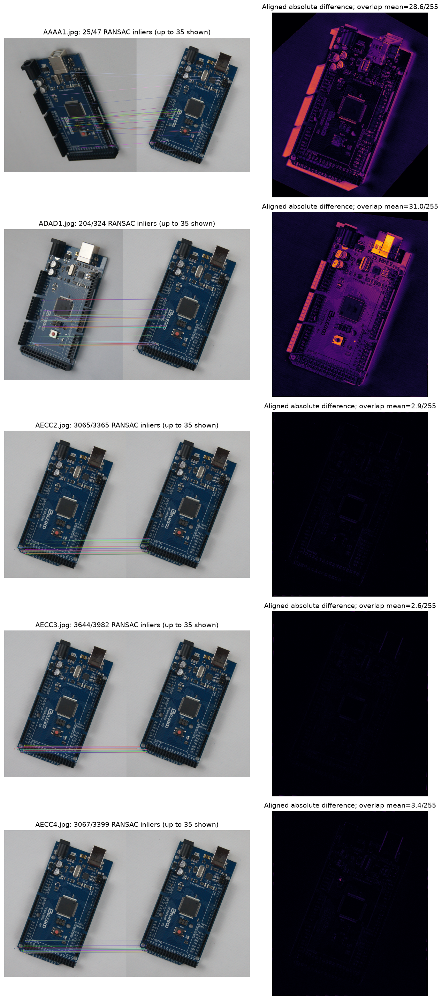

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pcb_dir = Path("images_02/pcbs")
template_path = pcb_dir / "AECC1.jpg"
image_paths = sorted(p for p in pcb_dir.glob("*.jpg") if p != template_path)
assert len(image_paths) == 5, "Expected five PCB images besides AECC1.jpg"

# Resize both images by the same factor for faster SIFT/matching; all coordinates
# and the final difference map are in the resized template's pixel coordinates.
def load_small(path, max_side=1400):
    image = cv.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    scale = min(1., max_side / max(image.shape[:2]))
    return cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA) if scale < 1 else image

template = load_small(template_path)
sift = cv.SIFT_create()
matcher = cv.BFMatcher(cv.NORM_L2)
key_t, desc_t = sift.detectAndCompute(cv.cvtColor(template, cv.COLOR_BGR2GRAY), None)
assert desc_t is not None

fig, axes = plt.subplots(len(image_paths), 2, figsize=(12, 25))
summary = []
for row, path in enumerate(image_paths):
    image = load_small(path)
    key_i, desc_i = sift.detectAndCompute(cv.cvtColor(image, cv.COLOR_BGR2GRAY), None)
    if desc_i is None or len(desc_i) < 4:
        print(f"{path.name}: not enough SIFT descriptors")
        continue
    # Keep distinctive matches; RANSAC filters remaining outliers.
    pairs = matcher.knnMatch(desc_i, desc_t, k=2)
    good = [m for m, n in pairs if m.distance < 0.75 * n.distance]
    if len(good) < 4:
        print(f"{path.name}: only {len(good)} reliable matches; cannot estimate homography")
        continue
    src = np.float32([key_i[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([key_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inlier_mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    if H is None or inlier_mask.sum() < 4:
        print(f"{path.name}: RANSAC homography failed")
        continue
    inliers = inlier_mask.ravel().astype(bool)
    display_matches = [m for m, keep in zip(good, inliers) if keep][:35]
    montage = cv.drawMatches(image, key_i, template, key_t, display_matches, None,
                             flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    size = (template.shape[1], template.shape[0])
    aligned = cv.warpPerspective(image, H, size)
    valid = cv.warpPerspective(np.ones(image.shape[:2], dtype=np.uint8), H, size) > 0
    # Mask non-overlap: black warp borders should not be mistaken for PCB defects.
    difference = cv.absdiff(aligned, template)
    diff_gray = cv.cvtColor(difference, cv.COLOR_BGR2GRAY)
    diff_gray[~valid] = 0
    mean_diff = float(diff_gray[valid].mean()) if valid.any() else float("nan")
    summary.append((path.name, len(good), int(inliers.sum()), mean_diff, valid.mean()))
    axes[row, 0].imshow(cv.cvtColor(montage, cv.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{path.name}: {inliers.sum()}/{len(good)} RANSAC inliers (up to 35 shown)")
    axes[row, 1].imshow(diff_gray, cmap="inferno", vmin=0, vmax=255)
    axes[row, 1].set_title(f"Aligned absolute difference; overlap mean={mean_diff:.1f}/255")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
print("Image | ratio-test matches | RANSAC inliers | overlap mean absolute gray difference | overlap fraction")
for record in summary:
    print(f"{record[0]:10s} | {record[1]:4d} | {record[2]:4d} | {record[3]:6.1f} | {record[4]:.2%}")


**What the images show.** The match panels show which details were trusted for alignment. In the difference panels, brighter areas mean the aligned pictures look less alike, **not necessarily that a component is faulty**. AECC2–4 are close to the reference in this run (average differences about 2.6–3.4 out of 255); AAAA1 and ADAD1 differ more (about 28.6–31.0). An angled camera, raised USB port or buttons, shadows, and lighting can all create differences. The printed match counts may change slightly because the matching step was simplified; the overall comparison remains similar.
